# Reconstruct/Play a sound from the power spectrum

In our project, we have *Power Spectrum FFT's*, where we have only $|a_f|^2$ of the *complex* amplitude $a_f$, at frequency $f$.  
Thus, we have truncated the information from the full (complex) FFT, by half.

Can we still reconstruct and play the *time-domain* sound, starting only from the power spectrum?

---

From NB1:

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import simpleaudio as sa

frequency = 261  # C3
fs = 44100  # 44100 samples per second
seconds = 3  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * fs, False)

# Generate a 440 Hz sine wave
note = np.sin(frequency * t * 2 * np.pi)

# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

# Start playback
play_obj = sa.play_buffer(audio, 1, 2, fs)

# Wait for playback to finish before exiting
play_obj.wait_done()

Let's create a C3 *marimba tone* (partials 1:4:10  see http://www.lafavre.us/tuning-marimba.htm )

In [20]:
frequency = 130  # Our played note will be 440 Hz
samplerate = 44100  # 44100 samples per second
seconds = 1  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * samplerate, False)

# Generate a 440 Hz sine wave
note =        np.sin(     frequency * t * 2 * np.pi) + \
       0.5  * np.sin( 4 * frequency * t * 2 * np.pi) + \
       0.25 * np.sin(10 * frequency * t * 2 * np.pi)

# with envelope
#note = (np.sin(frequency * t * 2 * np.pi) + \
#       np.sin(4 * frequency * t * 2 * np.pi) + \
#       np.sin(10 * frequency * t * 2 * np.pi)) * np.exp(-10*t)

# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

# Start playback
play_obj = sa.play_buffer(audio, 1, 2, samplerate)

# Wait for playback to finish before exiting
play_obj.wait_done()

The *note* (in time-domain)

In [6]:
note

array([ 0.   ,  0.102,  0.201, ..., -0.298, -0.201, -0.102])

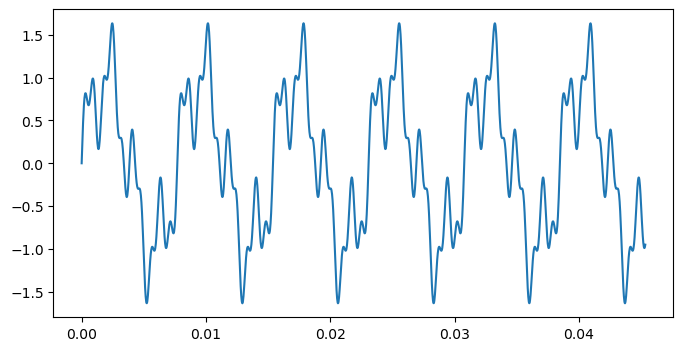

In [7]:
#%matplotlib inline

plt.figure(figsize=(8,4))
plt.plot(t[:2000], note[:2000], '-')

---

## FFT

In [8]:
from scipy.fftpack import fft, ifft

noteFFT = fft(note)

**Real part**

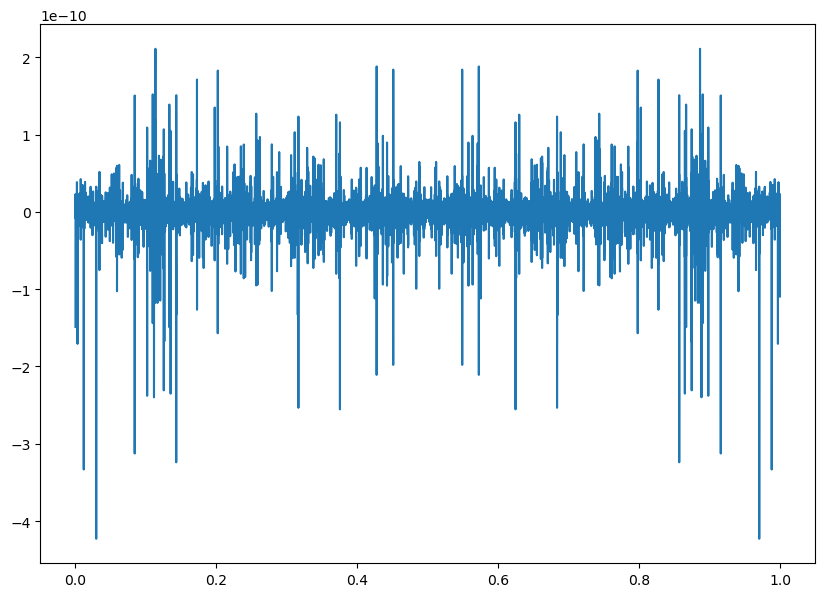

In [9]:
plt.plot(t, noteFFT.real)

Note range ($10^{-10} \sim 0$)

**Complex part**

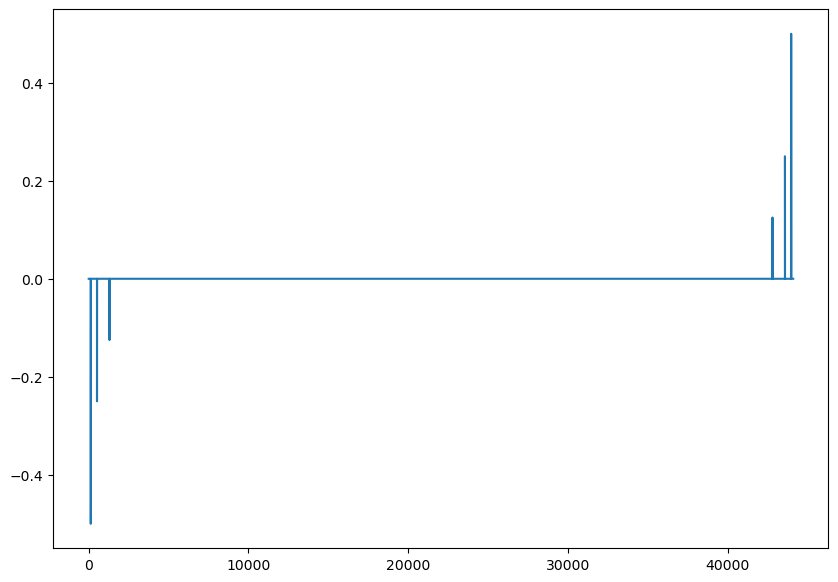

In [7]:
plt.plot(range(len(noteFFT)), noteFFT.imag/44100)

There's the 1:4:10

Also, $H(f) = H^*(-f)$ as described in NR, since note(t) is real.

In [446]:
len(noteFFT)/2

22050.0

In [470]:
halflen = int(len(noteFFT)/2)

## Power spectrum

Let N=8, then scematically, the FFT looks like this: 

<pre>
[ 0 ][ 1 ][ 2 ][ 3 ][ 4 ][ 5 ][ 6 ][ 7 ]  
zero  f1   f2   f3   f4   -f3  -f2  -f1  
                    -f4 
</pre>

N=8, halflen = 4

* `noteFFT[0]` is the zero-mode ($a_{f=0}$).
* `noteFFT[1:halflen+1]` is the +freq set
* `noteFFT[halflen+1:]` is the -freq set

Make power spectrum--assuming that the zero mode is left out, hence `power` starts from `noteFFT[1:]`

In [448]:
power = np.abs(noteFFT[1:halflen+1])

Text(0.5, 1.0, 'Power spectrum of the marimba tone')

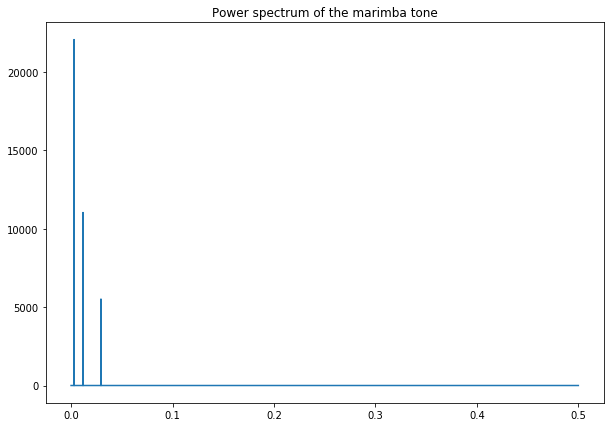

In [449]:
plt.plot(t[:halflen], power)
plt.title('Power spectrum of the marimba tone')

In [450]:
len(power)

22050

Now, from the *power spectrum*, we can reconstruct an actual FFT, then the corresponding *sound*

In [451]:
trialFFT = power * 1j

In [452]:
len(trialFFT)

22050

In [453]:
trialFFT = np.insert(trialFFT, 0, 0+0j)

In [454]:
trialFFT

array([ 0.+0.j,  0.+0.j,  0.+0.j, ...,  0.+0.j,  0.+0.j,  0.+0.j])

In [455]:
len(trialFFT)

22051

**Example** 

Get the slicing correct:

In [456]:
x = [0,1,2,3,4,5,6,7]

In [457]:
x[-2:0:-1]

[6, 5, 4, 3, 2, 1]

In [458]:
x[0:] + x[-2:0:-1]

[0, 1, 2, 3, 4, 5, 6, 7, 6, 5, 4, 3, 2, 1]

Now, use the reversed, sliced power to add the $-f$ portion of .

In [459]:
trialFFT = np.append(trialFFT, -trialFFT[-2:0:-1])

In [460]:
trialFFT

array([ 0.+0.j,  0.+0.j,  0.+0.j, ..., -0.-0.j, -0.-0.j, -0.-0.j])

In [461]:
len(trialFFT)

44100

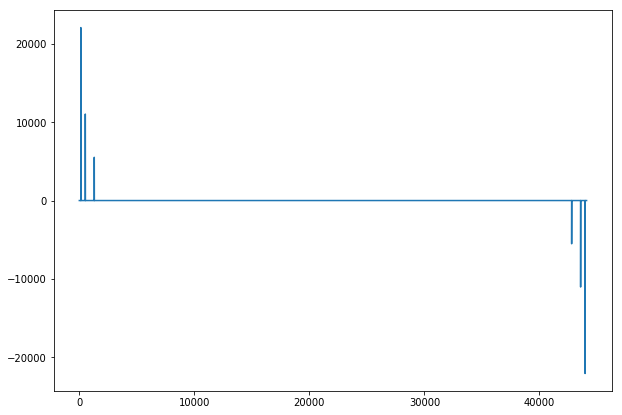

In [462]:
plt.plot(range(len(trialFFT.real)), trialFFT.imag)

In [463]:
note2 = ifft(-trialFFT.imag * 1j)

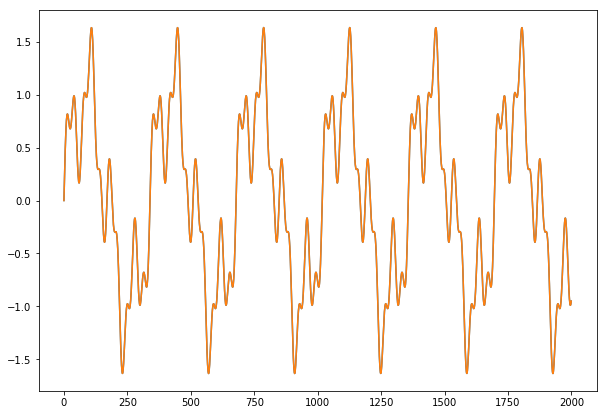

In [464]:
plt.plot(range(len(note2))[:2000], note2.real[:2000])
plt.plot(range(len(note))[0:2000], note[:2000])

$\large{\checkmark}$

---

### Add noise to the FFT

In [474]:
power = np.abs(noteFFT[1:halflen+1])
#noise = 1 * np.random.normal(0,1,halflen)**2
#power = power + noise

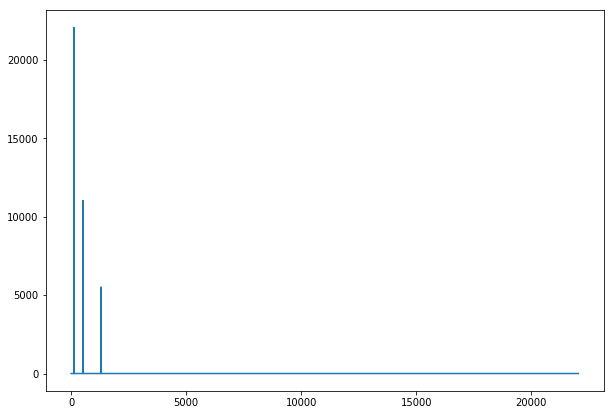

In [477]:
plt.plot(range(len(power)), power)
#plt.yscale('log')

In [478]:
trialFFT = power * 1j
trialFFT = np.insert(trialFFT, 0, 0+0j)
trialFFT = np.append(trialFFT, -trialFFT[-2:0:-1])

trialFFT[0] = 0
trialFFT[halflen-1] = 0 

In [479]:
for i in range(halflen-10, halflen+10):
    print(i,trialFFT[i], trialFFT[4094-i])

22040 4.32147439167e-13j (-0-1.16417212259e-12j)
22041 4.2892773854e-12j (-0-3.97545677569e-12j)
22042 2.78618591028e-12j (-0-8.97142916367e-12j)
22043 5.87094532301e-12j (-0-7.2248493095e-12j)
22044 2.9417226489e-12j (-0-1.09111744314e-11j)
22045 3.61549931431e-12j (-0-2.07955343258e-12j)
22046 5.35736438785e-12j (-0-1.9395479518e-11j)
22047 2.85832463479e-12j (-0-1.31451482103e-11j)
22048 2.87185714835e-12j (-0-1.36570248537e-11j)
22049 0j (-0-1.56581827538e-11j)
22050 2.74218648145e-12j (-0-2.65821043472e-12j)
22051 (-0-2.67338634329e-12j) (-0-1.16139475552e-11j)
22052 (-0-2.87185714835e-12j) (-0-7.45977096005e-12j)
22053 (-0-2.85832463479e-12j) (-0-4.88359001762e-12j)
22054 (-0-5.35736438785e-12j) (-0-9.90748287364e-12j)
22055 (-0-3.61549931431e-12j) (-0-6.19973115602e-12j)
22056 (-0-2.9417226489e-12j) (-0-7.30447839074e-12j)
22057 (-0-5.87094532301e-12j) (-0-3.48741531128e-12j)
22058 (-0-2.78618591028e-12j) (-0-6.03290916753e-12j)
22059 (-0-4.2892773854e-12j) (-0-6.36046745647e-13

In [480]:
note2 = ifft(-trialFFT * 1j)

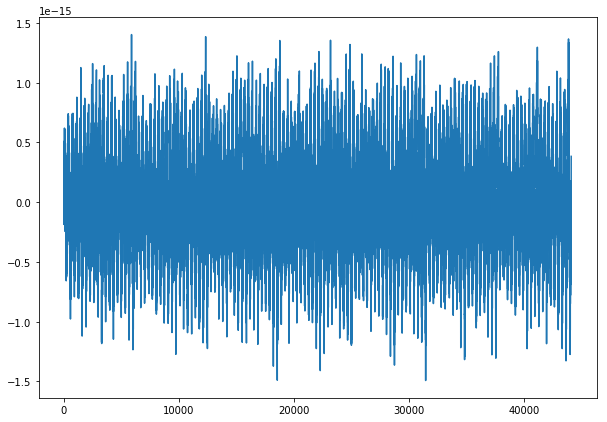

In [481]:
plt.plot(range(len(note2)), note2)

---

### Reproduce a bank sound

In [11]:
srcfile = '../OldFFTBank/flu-a5-ord-mf.nbb'

f = np.fromfile(srcfile, dtype='float32')

In [12]:
len(f)

2048

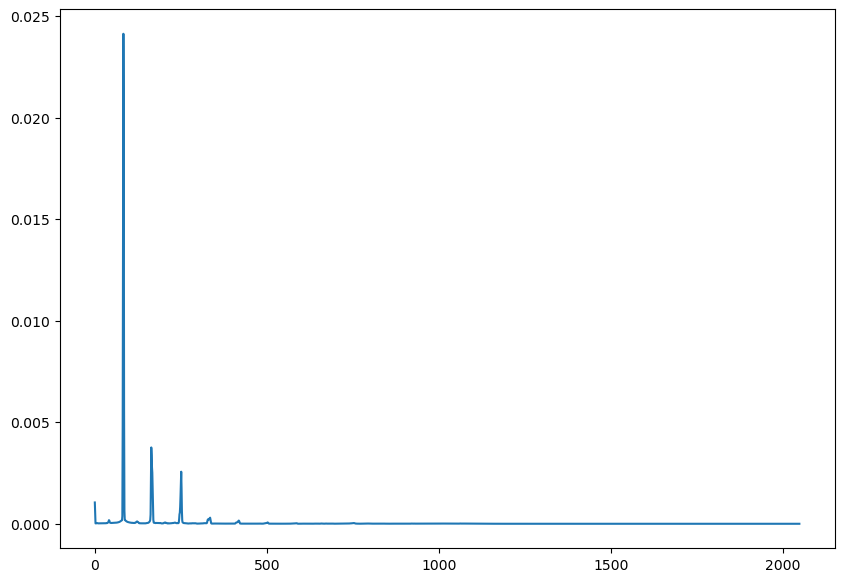

In [13]:
plt.plot(range(len(f)), f, '-')
#plt.yscale('log')
#plt.xlim(80,87)

**Question**: for the Bank power spectra, does the first value represent $f=10.76$ Hz, or $f=0$ Hz?

In [14]:
np.argmax(f)

83

In [15]:
f[80:87]

array([0.   , 0.005, 0.015, 0.024, 0.02 , 0.006, 0.001], dtype=float32)

In [18]:
10.766*83

893.578

In [17]:
1323.48 / 329.63

4.015047174104299

An E4 is approximately 330 Hz (329.63).   
The maximum peak in the above power spectrum is at index 123.  
123 * 10.76 Hz = 4.015...  about 4x the E4.

This means that index 123 corresponds to the 123rd freq. bin.

My conclusion: f[0] -> $f_1$, *i.e.* the zero-mode

Hence we *do **NOT** have to add in the zero-mode*.

In [401]:
trialFFT = f

In [402]:
trialFFT[0] = 0

In [403]:
trialFFT = np.append(f, -f[-2:0:-1])

In [404]:
len(trialFFT)

4094

In [405]:
trialFFT = trialFFT * 1j

In [406]:
for i in range(2040, 2060):
    print(i,trialFFT[i], trialFFT[4094-i])

2040 1.27295e-06j (-0-1.27295e-06j)
2041 1.27576e-06j (-0-1.27576e-06j)
2042 1.28561e-06j (-0-1.28561e-06j)
2043 1.27767e-06j (-0-1.27767e-06j)
2044 1.26695e-06j (-0-1.26695e-06j)
2045 1.27302e-06j (-0-1.27302e-06j)
2046 1.28262e-06j (-0-1.28262e-06j)
2047 1.27338e-06j 1.27338e-06j
2048 (-0-1.28262e-06j) 1.28262e-06j
2049 (-0-1.27302e-06j) 1.27302e-06j
2050 (-0-1.26695e-06j) 1.26695e-06j
2051 (-0-1.27767e-06j) 1.27767e-06j
2052 (-0-1.28561e-06j) 1.28561e-06j
2053 (-0-1.27576e-06j) 1.27576e-06j
2054 (-0-1.27295e-06j) 1.27295e-06j
2055 (-0-1.27436e-06j) 1.27436e-06j
2056 (-0-1.28463e-06j) 1.28463e-06j
2057 (-0-1.24479e-06j) 1.24479e-06j
2058 (-0-1.29714e-06j) 1.29714e-06j
2059 (-0-1.2719e-06j) 1.2719e-06j


In [407]:
trialFFT[0] = 0
trialFFT[2047] = 0 

In [408]:
len(trialFFT)

4094

In [409]:
obonote = ifft(-trialFFT*len(trialFFT))

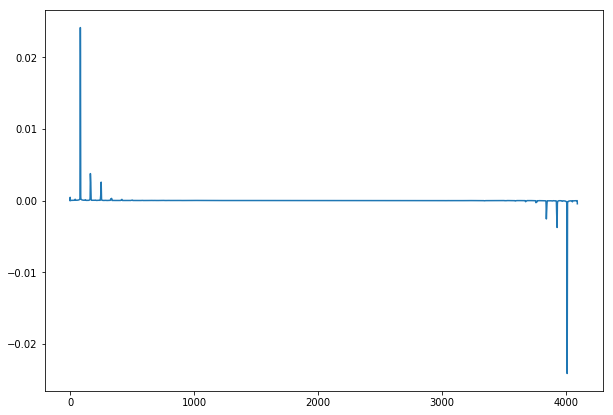

In [410]:
plt.plot(range(len(trialFFT)), trialFFT.imag, '-')
#plt.yscale('log')

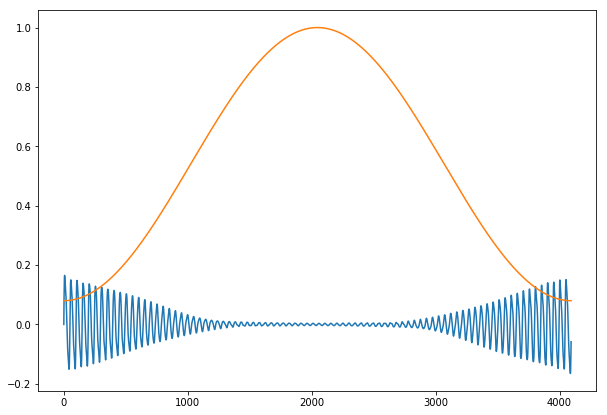

In [496]:
plt.plot(range(len(obonote)), obonote, '-')
#plt.plot(range(len(obonote)), np.hamming(len(obonote)) )

In [483]:
len(obonote)

4094

In [275]:
trialFFT[1]

0.00044775498j

In [276]:
trialFFT[-1]

(-0-0.00044775498j)

In [271]:
trialFFT[0]

0j

---

## Construct the sound "by hand"

In [281]:
f = np.fromfile('../Banknbb/pno-c3-ord-mf.nbb', dtype='float32')

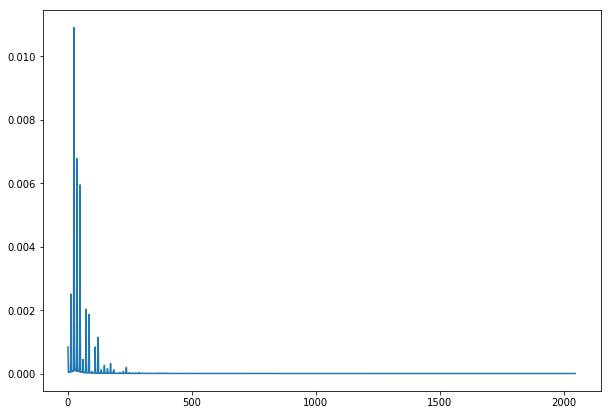

In [282]:
plt.plot(range(len(f)), f, '-')

In [354]:
freqdelta = 44100/4096  # Our played note will be 440 Hz
freqdelta = 10.8
samplerate = 44100  # 44100 samples per second
seconds = 1  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * samplerate, False)

# Generate sound
note = np.zeros(seconds*samplerate)
for n in range(15):
    note += f[n] * np.sin( n * freqdelta * t * 2 * np.pi) 

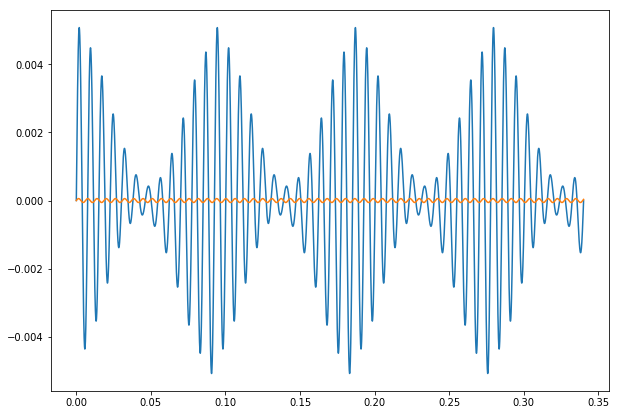

In [355]:
plt.plot(t[:15000], note[:15000])
n = 15
plt.plot(t[:15000], f[n] * np.sin( n * freqdelta * t * 2 * np.pi)[:15000])

In [291]:
# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

In [293]:
# Start playback
play_obj = sa.play_buffer(audio, 1, 2, samplerate)

# Wait for playback to finish before exiting
play_obj.wait_done()

In [129]:
trialFFT[1]

0.00094051793j

In [146]:
srcfile = '../Banknbb/flu-a6-ord-mf.nbb'

powA6 = np.fromfile(srcfile, dtype='float32')

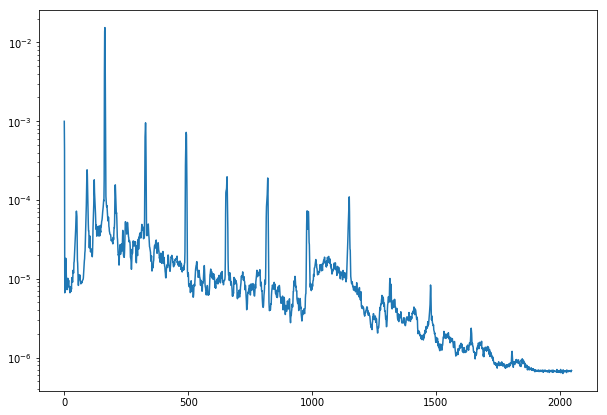

In [151]:
plt.plot(range(len(powA4)), powA4, '-')
plt.yscale('log')

In [148]:
np.argmax(powA6)

164

In [150]:
10.76 * 163

1753.8799999999999